# 03H 基础 MIMO LMMSE 检测

本实验是对 Sionna 自带示例的课程化简化版本。请补全 TODO 并解释关键参数对结果的影响。

In [1]:
# 导入依赖，并准备 2x2 MIMO flat fading 链路。
from pathlib import Path
import sys

if hasattr(sys.stdout, "reconfigure"):   # 交互式内核的 OutStream 没有该接口
    sys.stdout.reconfigure(encoding="utf-8")

for p in [Path.cwd(), *Path.cwd().parents]:
    if (p / "src" / "sionna").exists():
        sys.path.insert(0, str(p / "src"))
        break

import numpy as np
import torch
import matplotlib.pyplot as plt

DEVICE = "cpu"
PRECISION = "single"

# 固定所有随机源（含 Sionna 内部 RNG），保证 notebook 反复执行结果一致
from sionna.phy import config as sionna_config

torch.manual_seed(42)
np.random.seed(42)
sionna_config.seed = 42

plt.rcParams.update(
    {
        "font.sans-serif": [
            "Microsoft YaHei",
            "SimHei",
            "Noto Sans CJK SC",
            "Arial Unicode MS",
            "DejaVu Sans",
        ],
        "axes.unicode_minus": False,
        "font.size": 13,
        "axes.labelsize": 13,
        "xtick.labelsize": 12,
        "ytick.labelsize": 12,
        "legend.fontsize": 11,
        "figure.dpi": 200,
        "savefig.dpi": 200,
    }
)

FIG_DIR = Path.cwd() / "figures"
DATA_DIR = Path.cwd() / "data"
FIG_DIR.mkdir(parents=True, exist_ok=True)
DATA_DIR.mkdir(parents=True, exist_ok=True)

from sionna.phy.mapping import Constellation, Mapper, Demapper
from sionna.phy.channel import FlatFadingChannel
from sionna.phy.mimo import lmmse_equalizer

NUM_TX = 2
NUM_RX = 2
NUM_BITS_PER_SYMBOL = 2
PRECISION = "single"
const = Constellation("qam", NUM_BITS_PER_SYMBOL, precision=PRECISION, device=DEVICE)
mapper = Mapper(constellation=const, precision=PRECISION, device=DEVICE)
demapper = Demapper(
    "app", constellation=const, hard_out=False, precision=PRECISION, device=DEVICE
)
channel = FlatFadingChannel(
    NUM_TX, NUM_RX, return_channel=True, precision=PRECISION, device=DEVICE
)


def ebno_db_to_no(ebno_db, nbits):
    ebno = 10 ** (torch.as_tensor(ebno_db, dtype=torch.float32, device=DEVICE) / 10.0)
    return 1.0 / (ebno * nbits)


def hard_bits(llr):
    return (llr > 0).to(torch.int32)


def ber(b, b_hat):
    return float(
        torch.mean((b.to(torch.int32) != b_hat.to(torch.int32)).float()).item()
    )


print("2x2 MIMO 平坦衰落链路初始化完成：QPSK 调制、LMMSE 均衡器、Sionna 信道均就绪。")

2x2 MIMO 平坦衰落链路初始化完成：QPSK 调制、LMMSE 均衡器、Sionna 信道均就绪。


表 1  2x2 MIMO LMMSE 检测误比特率（Sionna 信道，每点 81920 个比特）
  Eb/N0 (dB)   BER
         0     1.066e-01
         3     6.481e-02
         6     3.630e-02
         9     2.002e-02
        12     9.778e-03


图题：2x2 平坦衰落 MIMO 系统中 LMMSE 检测的误比特率曲线


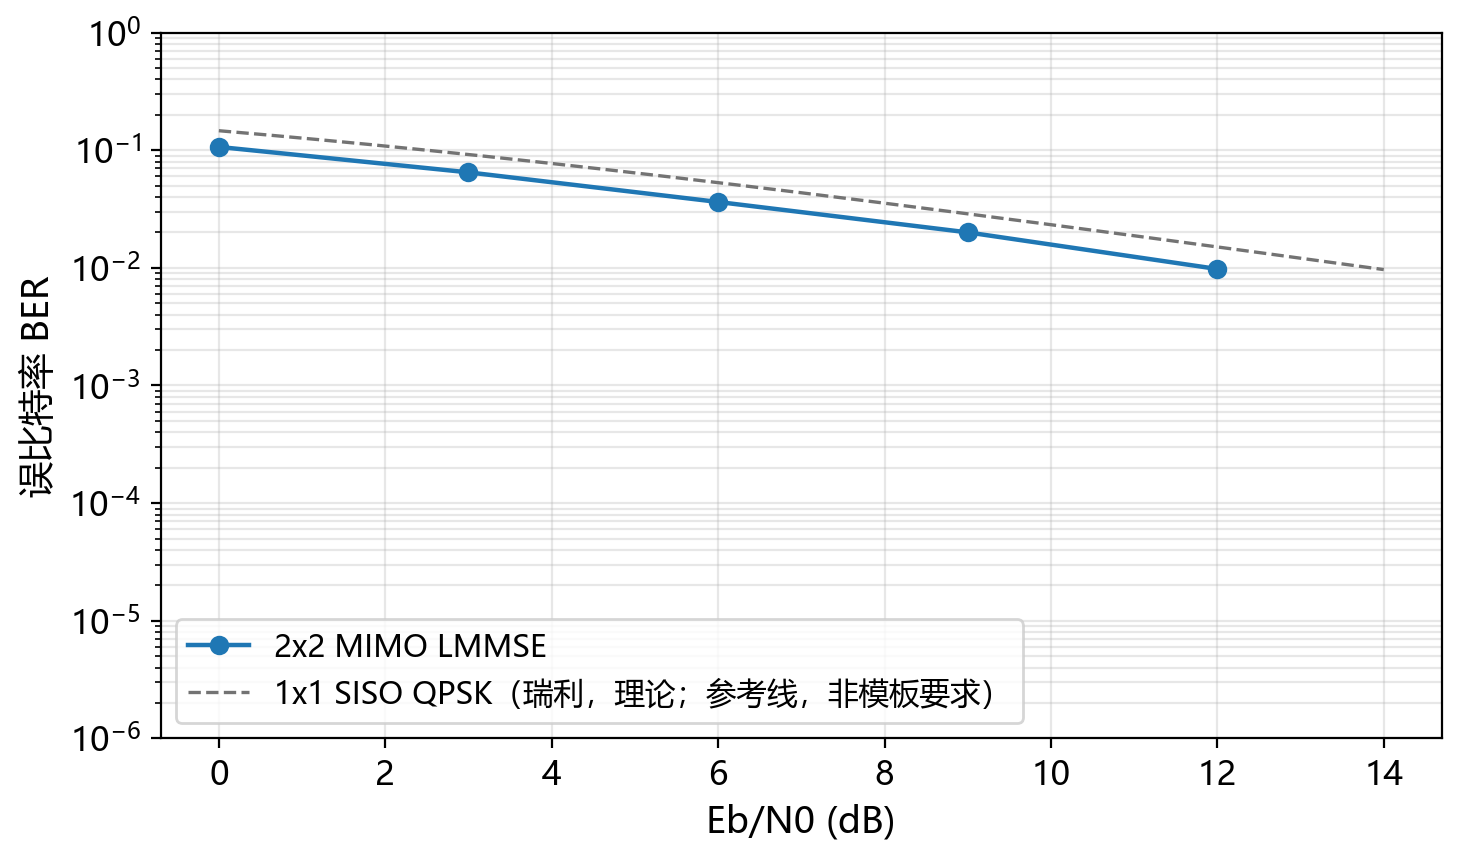

已保存数据：03H_ber_lmmse_sionna.csv


In [2]:
# 使用 Sionna FlatFadingChannel 和 LMMSE equalizer 计算 2x2 MIMO BER。
def run_mimo_ber(ebno_db, batch_size=2048, num_reps=10):
    """估计 2x2 平坦衰落 MIMO + LMMSE 均衡在给定 Eb/N0 下的误比特率。

    每个复维噪声功率 N0 = 1 / (Eb/N0 * 每符号比特数)，QPSK 星座归一化为 Es = 1，
    因此每根发射天线上的符号信噪比为 Es/N0 = 2 * Eb/N0。
    为压低高信噪比处的统计涨落，内部独立重复 num_reps 次再合并统计。
    """
    nbits = NUM_TX * NUM_BITS_PER_SYMBOL
    no = ebno_db_to_no(ebno_db, NUM_BITS_PER_SYMBOL)
    # 白噪声协方差 S = N0 * I（LMMSE 均衡器需要显式给出）
    s = no * torch.eye(NUM_RX, dtype=torch.complex64, device=DEVICE)

    error_sum = 0.0
    bit_sum = 0
    for _ in range(num_reps):
        # 1) 生成比特并按 QPSK 映射到 2 根发射天线（2 个符号）
        bits = torch.randint(0, 2, (batch_size, nbits), device=DEVICE)
        x = mapper(bits)                                  # [B, NUM_TX]
        # 2) 通过 2x2 平坦瑞利信道，得到接收信号 y 与信道矩阵 h
        y, h = channel(x, no)                             # [B, NUM_RX], [B, NUM_RX, NUM_TX]
        # 3) LMMSE 均衡：x_hat = diag(GH)^-1 G y，G = H^H (H H^H + S)^-1
        x_hat, no_eff = lmmse_equalizer(y, h, s, precision=PRECISION)
        # 4) 用 APP 解映射得到每比特 LLR，再硬判决并统计误比特
        llr = demapper(x_hat, no_eff)                     # [B, nbits]
        error_sum += ber(bits, hard_bits(llr)) * bits.numel()
        bit_sum += bits.numel()
    return error_sum / bit_sum


ebno_db = np.arange(0, 15, 3)

mimo_ber = [run_mimo_ber(v) for v in ebno_db]

print("表 1  2x2 MIMO LMMSE 检测误比特率（Sionna 信道，每点 %d 个比特）"
      % (2048 * 10 * NUM_TX * NUM_BITS_PER_SYMBOL))
print("  Eb/N0 (dB)   BER")
for _e, _b in zip(ebno_db, mimo_ber):
    print(f"  {_e:>8.0f}     {_b:.3e}")

def siso_qpsk_theory(ebno_db):
    """1x1 SISO 瑞利衰落 + QPSK 的理论 BER（Proakis L=1 闭式，gamma_bar = Eb/N0）。

    注意：QPSK 的 Es/N0 = 2 Eb/N0，但闭式 Pb=0.5(1-sqrt(g/(1+g))) 中的 g 是平均**比特**
    信噪比 Eb/N0，不能代 Es/N0；早期版本误乘 2 使参考线整体乐观 3.01 dB。
    """
    g = 10.0 ** (np.asarray(ebno_db, dtype=float) / 10.0)
    mu = np.sqrt(g / (1.0 + g))
    return 0.5 * (1.0 - mu)


_ebno_dense = np.linspace(0.0, 14.0, 141)

plt.figure(figsize=(7.5, 4.5))
plt.semilogy(ebno_db, np.array(mimo_ber) + 1e-6, "o-", lw=1.6, ms=6, label="2x2 MIMO LMMSE")
plt.semilogy(_ebno_dense, siso_qpsk_theory(_ebno_dense), "--", color="0.45", lw=1.2,
             label="1x1 SISO QPSK（瑞利，理论；参考线，非模板要求）")
plt.xlabel("Eb/N0 (dB)")
plt.ylabel("误比特率 BER")
plt.grid(True, which="both", alpha=0.3)
plt.ylim(1e-6, 1.0)
plt.legend(loc="lower left")
plt.tight_layout()
plt.savefig(FIG_DIR / "03H_ber_lmmse.png", dpi=200, bbox_inches="tight")
print("图题：2x2 平坦衰落 MIMO 系统中 LMMSE 检测的误比特率曲线")
plt.show()

assert len(mimo_ber) == len(ebno_db)

import pandas as pd

pd.DataFrame({"ebno_db": ebno_db, "ber_lmmse_sionna": mimo_ber}).to_csv(
    DATA_DIR / "03H_ber_lmmse_sionna.csv", index=False, encoding="utf-8-sig"
)
print("已保存数据：03H_ber_lmmse_sionna.csv")

## 补充：2×2 平坦衰落系统模型与信道条件数

模板主实验只给出 LMMSE 的一条 BER 曲线。为了解释"为什么 LMMSE 在低信噪比优于 ZF、
高信噪比又趋于 ZF"，先把系统模型中的关键统计量核清：

$$ \mathbf{y} = \mathbf{H}\mathbf{x} + \mathbf{n},\qquad
\mathbf{H}\in\mathbb{C}^{2\times 2},\ h_{ij}\sim\mathcal{CN}(0,1),\quad
\mathbf{n}\sim\mathcal{CN}(\mathbf{0},N_0\mathbf{I}),\quad \mathbb{E}|\mathbf{x}|^2=1. $$

其中信道矩阵的条件数 $\kappa(\mathbf{H})=\sigma_{\max}/\sigma_{\min}$ 直接决定 ZF
检测的噪声放大倍数：$\kappa$ 越接近 1，两条数据流越"正交"，ZF 越接近无干扰；
$\kappa$ 很大时 $\mathbf{H}^{\mathsf H}\mathbf{H}$ 接近奇异，ZF 会把噪声放大 $\kappa^2$ 倍，
这正是 LMMSE 用 $N_0\mathbf{I}$ 正则化要抑制的。下面同时核对 $h_{ij}$ 的功率与噪声方差。

表 2  03H MIMO 检测仿真主要参数
  发射/接收天线数            2 x 2                                   满复用，无发射分集
  主实验调制               QPSK（2 bit/符号）                          星座归一化 Es = 1
  补充对比调制              16-QAM（4 bit/符号）                        用于观察检测器差距随调制阶数的变化
  信道                  平坦瑞利衰落，h_ij ~ CN(0,1) i.i.d.            E|h_ij|^2 = 1，准静态（每符号独立）
  检测器                 LMMSE（主）、ZF、ML 穷举（对比）                   x_hat = W y，W 见公式
  噪声                  n ~ CN(0, N0 I)，N0 = 1/(Eb/N0 * 每符号比特数) Es/N0 = 每符号比特数 * Eb/N0
  蒙特卡洛                模板 2048x10 组；对比实验 2x10^5 组              QPSK 每点 4x10^5 bit
  随机种子                42（主）/ 2026、2027（补充单元）                  torch、numpy、Sionna 三处同时固定

  实测 E|h_ij|^2 = 0.9984（理论 1.0）
  实测接收残差方差 = 0.04980（理论 N0 = 0.05000）
  2x2 复高斯信道条件数：中位数 9.43 dB，90% 分位 17.53 dB，最大 60.16 dB


图题：2x2 MIMO 的 QPSK 星座与平坦瑞利信道条件数分布


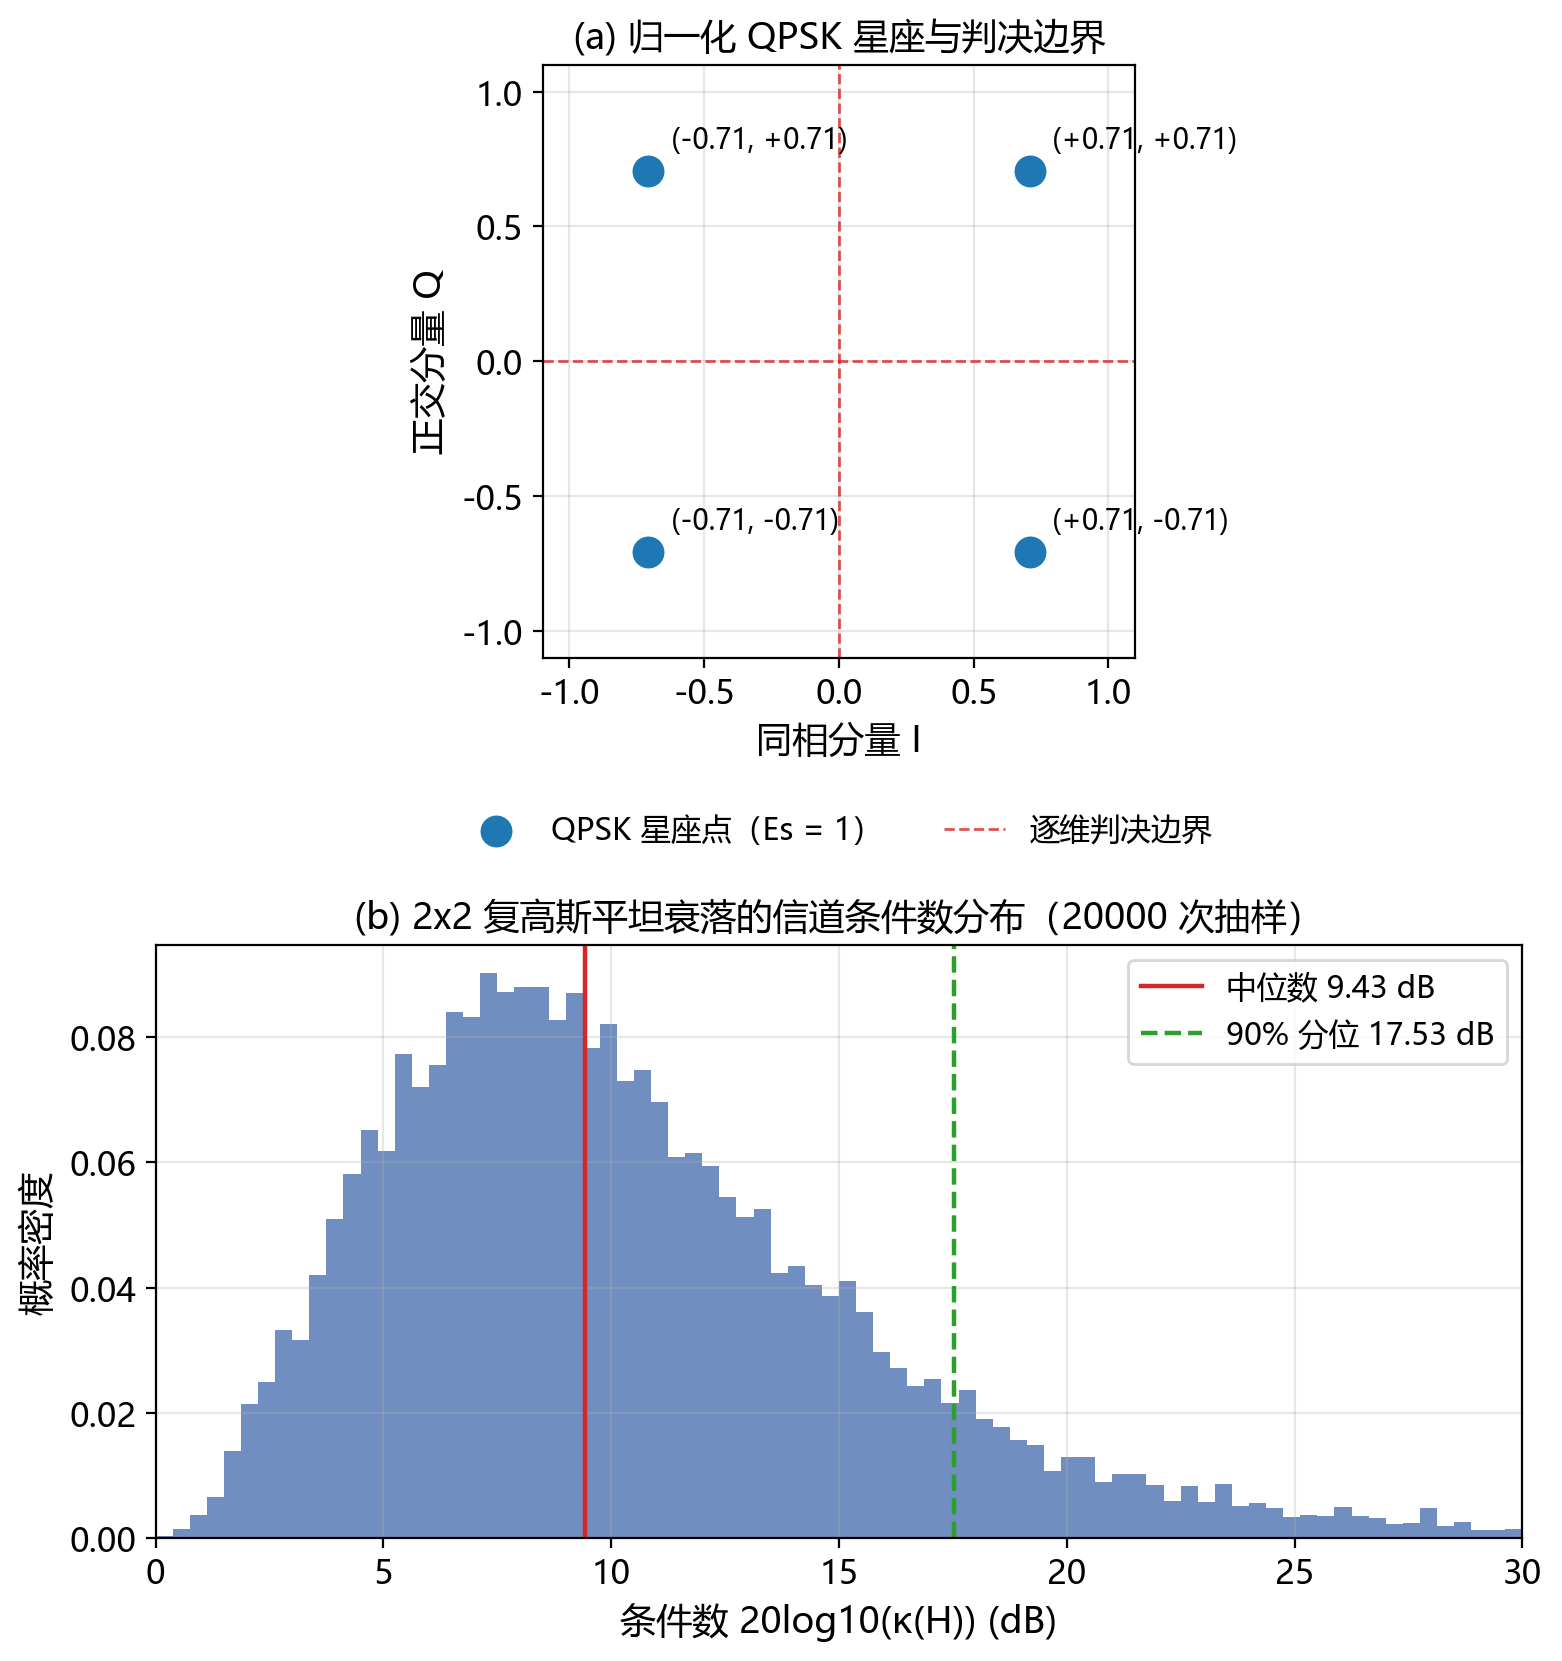

已保存数据：03H_channel_stats.csv

In [3]:
# 补充（过程性材料）：参数表、信道统计自检与 QPSK 星座/条件数分布
torch.manual_seed(2026)
sionna_config.seed = 2026


def cn(shape):
    """生成 CN(0,1) 复高斯随机量（实部/虚部各 N(0,1/2)，总复功率为 1）。"""
    z = torch.randn(*shape, device=DEVICE) + 1j * torch.randn(*shape, device=DEVICE)
    return (z / np.sqrt(2.0)).to(torch.complex64)


print("表 2  03H MIMO 检测仿真主要参数")
_parameters = [
    ("发射/接收天线数", "2 x 2", "满复用，无发射分集"),
    ("主实验调制", "QPSK（2 bit/符号）", "星座归一化 Es = 1"),
    ("补充对比调制", "16-QAM（4 bit/符号）", "用于观察检测器差距随调制阶数的变化"),
    ("信道", "平坦瑞利衰落，h_ij ~ CN(0,1) i.i.d.", "E|h_ij|^2 = 1，准静态（每符号独立）"),
    ("检测器", "LMMSE（主）、ZF、ML 穷举（对比）", "x_hat = W y，W 见公式"),
    ("噪声", "n ~ CN(0, N0 I)，N0 = 1/(Eb/N0 * 每符号比特数)", "Es/N0 = 每符号比特数 * Eb/N0"),
    ("蒙特卡洛", "模板 2048x10 组；对比实验 2x10^5 组", "QPSK 每点 4x10^5 bit"),
    ("随机种子", "42（主）/ 2026、2027（补充单元）", "torch、numpy、Sionna 三处同时固定"),
]
for _name, _value, _note in _parameters:
    print(f"  {_name:<20s}{_value:<40s}{_note}")

# --- 模型自检：E|h_ij|^2 是否为 1；信道输出残差方差是否为 N0 ---
torch.manual_seed(2026)
_batch = 20000
_bits = torch.randint(0, 2, (_batch, NUM_TX * NUM_BITS_PER_SYMBOL), device=DEVICE)
_x = mapper(_bits)
_no = ebno_db_to_no(10.0, NUM_BITS_PER_SYMBOL)
_y, _h = channel(_x, _no)
_res = _y - (_h @ _x.unsqueeze(-1)).squeeze(-1)
_h_power = float((_h.abs() ** 2).mean().item())
_no_meas = float((_res.abs() ** 2).mean().item())
_no_theory = float(_no.item())
print(f"\n  实测 E|h_ij|^2 = {_h_power:.4f}（理论 1.0）")
print(f"  实测接收残差方差 = {_no_meas:.5f}（理论 N0 = {_no_theory:.5f}）")
assert abs(_h_power - 1.0) < 0.05, "信道增益功率应归一化为 1"
assert abs(_no_meas / _no_theory - 1.0) < 0.1, "噪声方差应与 N0 一致"

# --- 条件数统计：kappa(H) = sigma_max / sigma_min ---
torch.manual_seed(2026)
_h_test = cn((20000, NUM_RX, NUM_TX))
_sv = torch.linalg.svdvals(_h_test)
_kappa = (_sv[:, 0] / _sv[:, 1]).cpu().numpy()
_kappa_db = 20.0 * np.log10(_kappa)
print(f"  2x2 复高斯信道条件数：中位数 {np.median(_kappa_db):.2f} dB，"
      f"90% 分位 {np.percentile(_kappa_db, 90):.2f} dB，最大 {_kappa_db.max():.2f} dB")

# --- 图 1：(a) QPSK 星座与判决边界；(b) 条件数分布 ---
fig, axes = plt.subplots(2, 1, figsize=(8.0, 8.5))

ax = axes[0]
_qpsk_pts = np.array([1 + 1j, 1 - 1j, -1 + 1j, -1 - 1j]) / np.sqrt(2.0)
ax.scatter(_qpsk_pts.real, _qpsk_pts.imag, s=110, c="#1f77b4", zorder=3, label="QPSK 星座点（Es = 1）")
ax.axhline(0.0, color="#d62728", ls="--", lw=1.0, alpha=0.8)
ax.axvline(0.0, color="#d62728", ls="--", lw=1.0, alpha=0.8, label="逐维判决边界")
for _k, _p in enumerate(_qpsk_pts):
    ax.annotate(f"({_p.real:+.2f}, {_p.imag:+.2f})", xy=(_p.real, _p.imag),
                xytext=(8, 8), textcoords="offset points", fontsize=10)
ax.set_xlabel("同相分量 I")
ax.set_ylabel("正交分量 Q")
ax.set_aspect("equal")
ax.set_xlim(-1.1, 1.1)
ax.set_ylim(-1.1, 1.1)
ax.set_title("(a) 归一化 QPSK 星座与判决边界", fontsize=13)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.22), ncol=2, frameon=False)
ax.grid(alpha=0.3)

ax = axes[1]
ax.hist(_kappa_db, bins=80, range=(0, 30), color="#4c72b0", alpha=0.8, density=True)
ax.axvline(np.median(_kappa_db), color="#d62728", lw=1.6,
           label=f"中位数 {np.median(_kappa_db):.2f} dB")
ax.axvline(np.percentile(_kappa_db, 90), color="#2ca02c", ls="--", lw=1.6,
           label=f"90% 分位 {np.percentile(_kappa_db, 90):.2f} dB")
ax.set_xlabel("条件数 20log10(κ(H)) (dB)")
ax.set_ylabel("概率密度")
ax.set_xlim(0, 30)
ax.set_title("(b) 2x2 复高斯平坦衰落的信道条件数分布（20000 次抽样）", fontsize=13)
ax.legend(loc="upper right")
ax.grid(alpha=0.3)

plt.tight_layout()
plt.savefig(FIG_DIR / "03H_channel_model.png", dpi=200, bbox_inches="tight")
print("图题：2x2 MIMO 的 QPSK 星座与平坦瑞利信道条件数分布")
plt.show()

df_stats = pd.DataFrame(
    {
        "metric": ["mean_h_power", "noise_var_measured", "noise_var_theory",
                   "kappa_median_db", "kappa_p90_db", "kappa_max_db"],
        "value": [_h_power, _no_meas, _no_theory,
                  float(np.median(_kappa_db)), float(np.percentile(_kappa_db, 90)),
                  float(_kappa_db.max())],
    }
)
df_stats.to_csv(DATA_DIR / "03H_channel_stats.csv", index=False, encoding="utf-8-sig")
print("已保存数据：03H_channel_stats.csv")

## 补充：自实现 ZF / LMMSE / ML 检测器对比（QPSK）

模板用库函数算了一条 LMMSE 曲线，这里把三种检测器都手写实现，在同一组随机信道/噪声上
比较（公共随机数，差异只来自检测算法本身）：

- **ZF**：$\mathbf{W}_{\rm ZF}=(\mathbf{H}^{\mathsf H}\mathbf{H})^{-1}\mathbf{H}^{\mathsf H}$
  —— 完全消除流间干扰，但会把噪声放大 $\kappa^2$ 倍；
- **LMMSE**：$\mathbf{W}_{\rm LMMSE}=(\mathbf{H}^{\mathsf H}\mathbf{H}+N_0\mathbf{I})^{-1}\mathbf{H}^{\mathsf H}$
  —— 用噪声功率正则化，在"抑制干扰"与"放大噪声"之间折中，低信噪比明显优于 ZF，
  高信噪比时 $N_0\to 0$ 退化为 ZF；
- **ML**：$\hat{\mathbf{x}}=\arg\min_{\mathbf{x}\in\mathcal{S}^2}\|\mathbf{y}-\mathbf{H}\mathbf{x}\|^2$
  —— 穷举 16 个 QPSK 符号对，是 2×2 空间复用的最优检测（性能上界）。

三种检测器都按 $\hat{\mathbf{x}}=\mathbf{W}\mathbf{y}/\mathrm{diag}(\mathbf{W}\mathbf{H})$
做偏置归一化，再逐维硬判决，从而保证比较的是同一判决规则。

一致性检验：Sionna LMMSE 与自实现 LMMSE 的硬判决比特一致率 = 100.000%



表 3  2x2 MIMO QPSK 三种检测器的误比特率（每点约 1x10^6 bit）
  Eb/N0 (dB)        ZF        LMMSE           ML
         0   1.465e-01   1.059e-01   8.705e-02
         2   1.083e-01   7.697e-02   5.329e-02
         4   7.690e-02   5.348e-02   2.862e-02
         6   5.317e-02   3.647e-02   1.438e-02
         8   3.517e-02   2.402e-02   6.620e-03
        10   2.297e-02   1.559e-02   2.922e-03
        12   1.516e-02   1.014e-02   1.243e-03
        14   9.840e-03   6.736e-03   5.677e-04
        16   6.092e-03   4.147e-03   1.979e-04
        18   4.045e-03   2.710e-03   8.646e-05
        20   2.481e-03   1.675e-03   4.792e-05
        22   1.665e-03   1.110e-03   9.375e-06


图题：2x2 MIMO QPSK 下 ZF / LMMSE / ML 检测器的误比特率对比


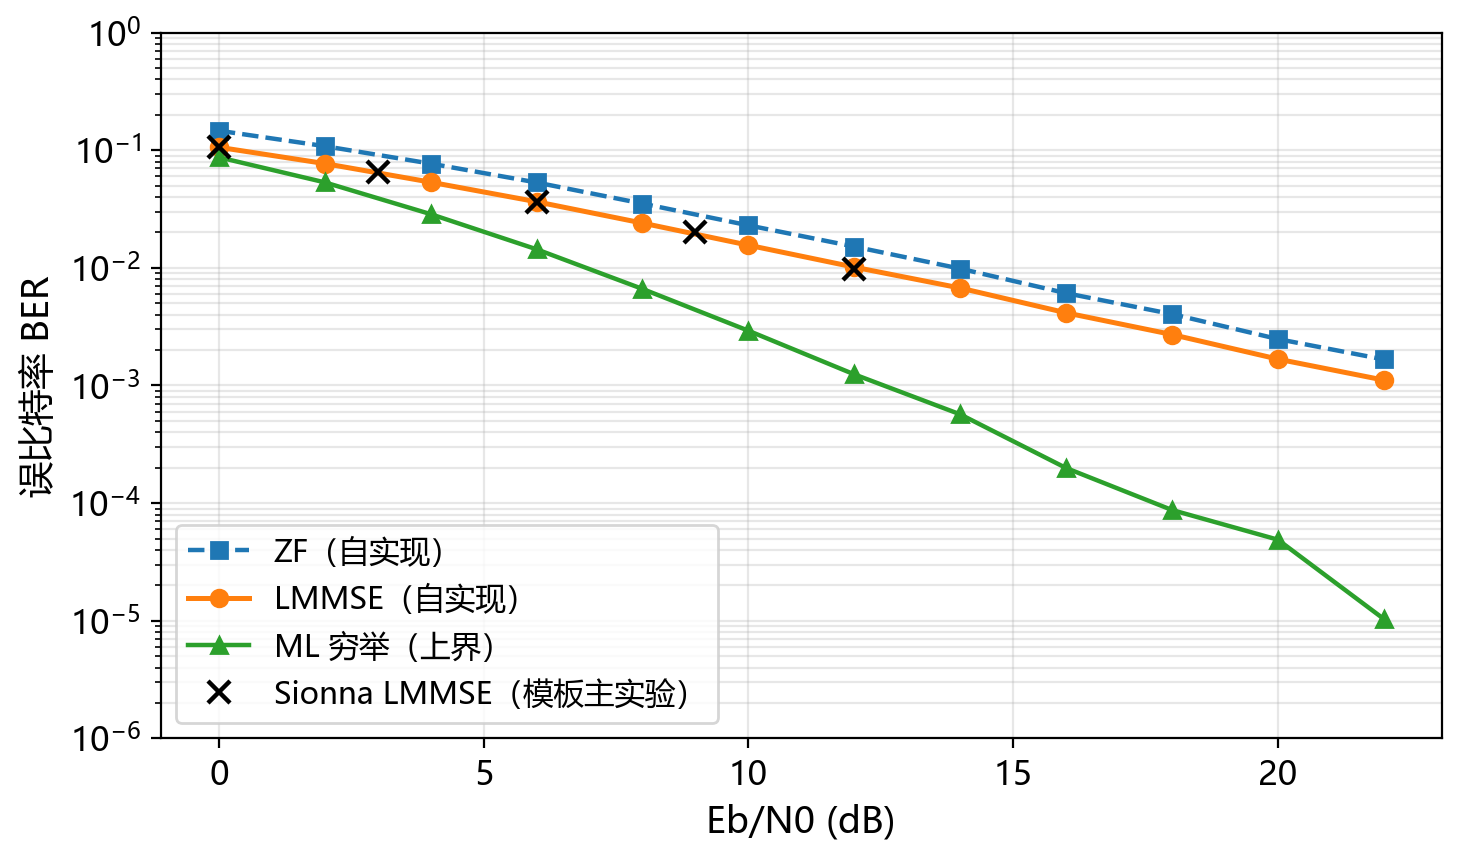

已保存数据：03H_detector_ber_qpsk.csv
断言通过：ML <= LMMSE <= ZF（BER 越低越好）。
结论：Eb/N0 = 4 dB 时，LMMSE 的 BER 比 ZF 低 30.5%，ML 又比 LMMSE 低 46.5%。


In [4]:
# 补充（核心对比）：自实现 ZF / LMMSE / ML 检测器（QPSK，2x2）
torch.manual_seed(2027)
sionna_config.seed = 2027


def inv2x2(a):
    """批量求 2x2 复矩阵的逆（写作闭式解，避免依赖库的通用求逆）。"""
    a11, a12 = a[..., 0, 0], a[..., 0, 1]
    a21, a22 = a[..., 1, 0], a[..., 1, 1]
    det = a11 * a22 - a12 * a21
    inv = torch.empty_like(a)
    inv[..., 0, 0] = a22 / det
    inv[..., 0, 1] = -a12 / det
    inv[..., 1, 0] = -a21 / det
    inv[..., 1, 1] = a11 / det
    return inv


def linear_estimate(y, h, no, detector):
    """自实现 ZF / LMMSE 线性检测：x_hat = diag(W H)^-1 W y，W 由闭式逆得到。"""
    hh = h.conj().transpose(-2, -1) @ h                 # H^H H，[B, K, K]
    if detector == "lmmse":
        hh = hh + no * torch.eye(NUM_TX, dtype=torch.complex64, device=DEVICE)
    w = inv2x2(hh) @ h.conj().transpose(-2, -1)         # [B, K, M]
    x_hat = (w @ y.unsqueeze(-1)).squeeze(-1)           # [B, K]
    d = torch.diagonal(w @ h, dim1=-2, dim2=-1).real    # diag(W H)
    return x_hat / d


def ml_estimate(y, h, points, chunk=4000):
    """自实现 ML 穷举检测：对每个符号向量枚举全部 points^K 个候选。"""
    k = points.numel()
    grid = torch.cartesian_prod(torch.arange(k, device=DEVICE), torch.arange(k, device=DEVICE))
    candidates = points[grid]                           # [P, K]
    best = torch.empty(y.shape[0], dtype=torch.long, device=DEVICE)
    for i0 in range(0, y.shape[0], chunk):
        i1 = min(i0 + chunk, y.shape[0])
        pred = torch.einsum("bmk,pk->bmp", h[i0:i1], candidates)   # [b, M, P]
        dist = ((y[i0:i1].unsqueeze(-1) - pred).abs() ** 2).sum(dim=1)  # [b, P]
        best[i0:i1] = dist.argmin(dim=-1)
    return candidates[best]


# QPSK 的 Gray 映射与逐维硬判决（b0 选 I 的符号，b1 选 Q 的符号）
QPSK_POINTS = torch.tensor([1 + 1j, 1 - 1j, -1 + 1j, -1 - 1j],
                           dtype=torch.complex64, device=DEVICE) / np.sqrt(2.0)


def qpsk_map(bits):
    i = (1.0 - 2.0 * bits[:, 0].float()) / np.sqrt(2.0)
    q = (1.0 - 2.0 * bits[:, 1].float()) / np.sqrt(2.0)
    return torch.complex(i, q).to(torch.complex64)


def qpsk_demap(x):
    return torch.stack(
        [(x.real < 0).to(torch.int64), (x.imag < 0).to(torch.int64)], dim=1
    )


def simulate_linear_ml(ebno_db_range, batch_size=80000, num_reps=3, mbs=2,
                       mapper_fn=qpsk_map, demapper_fn=qpsk_demap, points=QPSK_POINTS):
    """在公共随机信道/噪声上并行统计 ZF、LMMSE、ML 的 BER。"""
    results = {"zf": [], "lmmse": [], "ml": []}
    for ebno in ebno_db_range:
        no = 1.0 / (10.0 ** (ebno / 10.0) * mbs)   # 每复维噪声功率
        errors = {"zf": 0, "lmmse": 0, "ml": 0}
        total = 0
        for _ in range(num_reps):
            bits = torch.randint(0, 2, (batch_size, 2 * mbs), device=DEVICE)
            x = torch.stack(
                [mapper_fn(bits[:, :mbs]), mapper_fn(bits[:, mbs:])], dim=1
            )                                   # [B, K]
            h = cn((batch_size, NUM_RX, NUM_TX))
            y = (h @ x.unsqueeze(-1)).squeeze(-1) + np.sqrt(no) * cn((batch_size, NUM_RX))
            estimates = {
                "zf": linear_estimate(y, h, no, "zf"),
                "lmmse": linear_estimate(y, h, no, "lmmse"),
                "ml": ml_estimate(y, h, points),
            }
            for key, est in estimates.items():
                bits_hat = torch.cat(
                    [demapper_fn(est[:, 0]), demapper_fn(est[:, 1])], dim=1
                )
                errors[key] += int((bits != bits_hat).sum().item())
            total += bits.numel()
        for key in results:
            results[key].append(errors[key] / total)
    return {key: np.asarray(value) for key, value in results.items()}


# --- 先做一次一致性检验：自实现 LMMSE 与 Sionna lmmse_equalizer 判决应完全相同 ---
_check_bits = torch.randint(0, 2, (20000, NUM_TX * NUM_BITS_PER_SYMBOL), device=DEVICE)
_check_x = mapper(_check_bits)
_check_no = ebno_db_to_no(10.0, NUM_BITS_PER_SYMBOL)
_check_y, _check_h = channel(_check_x, _check_no)
_check_s = _check_no * torch.eye(NUM_RX, dtype=torch.complex64, device=DEVICE)
_x_lib, _no_eff = lmmse_equalizer(_check_y, _check_h, _check_s, precision=PRECISION)
_bits_lib = hard_bits(demapper(_x_lib, _no_eff))
_x_own = linear_estimate(_check_y, _check_h, float(_check_no.item()), "lmmse")
_bits_own = torch.cat([qpsk_demap(_x_own[:, 0]), qpsk_demap(_x_own[:, 1])], dim=1)
_match = float((_bits_lib == _bits_own).float().mean().item())
print(f"一致性检验：Sionna LMMSE 与自实现 LMMSE 的硬判决比特一致率 = {_match * 100:.3f}%")
assert _match > 0.999, "自实现 LMMSE 应与 Sionna 库函数给出相同判决"

# --- QPSK 主对比：BER vs Eb/N0 ---
ebno_cmp = np.arange(0, 23, 2)
qpsk_res = simulate_linear_ml(ebno_cmp)

print("\n表 3  2x2 MIMO QPSK 三种检测器的误比特率（每点约 1x10^6 bit）")
print("  Eb/N0 (dB)        ZF        LMMSE           ML")
for _i, _e in enumerate(ebno_cmp):
    print(f"  {_e:>8.0f}   {qpsk_res['zf'][_i]:.3e}   {qpsk_res['lmmse'][_i]:.3e}   "
          f"{qpsk_res['ml'][_i]:.3e}")

fig, ax = plt.subplots(figsize=(7.5, 4.5))
ax.semilogy(ebno_cmp, qpsk_res["zf"] + 1e-6, "s--", lw=1.6, ms=6, label="ZF（自实现）")
ax.semilogy(ebno_cmp, qpsk_res["lmmse"] + 1e-6, "o-", lw=1.8, ms=6, label="LMMSE（自实现）")
ax.semilogy(ebno_cmp, qpsk_res["ml"] + 1e-6, "^-", lw=1.6, ms=6, label="ML 穷举（上界）")
ax.semilogy(ebno_db, np.array(mimo_ber) + 1e-6, "kx", ms=8, mew=1.6,
            label="Sionna LMMSE（模板主实验）")
ax.set_xlabel("Eb/N0 (dB)")
ax.set_ylabel("误比特率 BER")
ax.set_ylim(1e-6, 1.0)
ax.grid(True, which="both", alpha=0.3)
ax.legend(loc="lower left")
plt.tight_layout()
plt.savefig(FIG_DIR / "03H_detector_ber_qpsk.png", dpi=200, bbox_inches="tight")
print("图题：2x2 MIMO QPSK 下 ZF / LMMSE / ML 检测器的误比特率对比")
plt.show()

pd.DataFrame({"ebno_db": ebno_cmp, **{f"ber_{k}": v for k, v in qpsk_res.items()}}).to_csv(
    DATA_DIR / "03H_detector_ber_qpsk.csv", index=False, encoding="utf-8-sig"
)
print("已保存数据：03H_detector_ber_qpsk.csv")

# 合理性断言：ML 最好、LMMSE 不劣于 ZF（留统计容差，低 BER 处误码计数很稀疏）
assert np.mean(qpsk_res["ml"]) <= np.mean(qpsk_res["lmmse"]) <= np.mean(qpsk_res["zf"])
assert np.all(qpsk_res["ml"] <= qpsk_res["lmmse"] * 1.05 + 1e-5), "ML 应是 BER 上界"
assert np.all(qpsk_res["lmmse"] <= qpsk_res["zf"] * 1.03 + 1e-5), "LMMSE 不应劣于 ZF"
print("断言通过：ML <= LMMSE <= ZF（BER 越低越好）。")

print(f"结论：Eb/N0 = {ebno_cmp[2]:.0f} dB 时，LMMSE 的 BER 比 ZF 低 "
      f"{(qpsk_res['zf'][2] - qpsk_res['lmmse'][2]) / qpsk_res['zf'][2] * 100:.1f}%，"
      f"ML 又比 LMMSE 低 {(qpsk_res['lmmse'][2] - qpsk_res['ml'][2]) / qpsk_res['lmmse'][2] * 100:.1f}%。")

## 补充：高阶调制（16-QAM）与增益量化

把同一套检测器推广到 16-QAM（每符号 4 bit，星座点取 $(\pm1,\pm3)/\sqrt{10}$，
Gray 映射）。调制阶数升高后，星座最小距离变小，检测器之间的差距被放大，
ML 相对线性检测的优势也更明显。最后用"达到目标 BER 所需 Eb/N0 + 曲线斜率"
把三者的增益与分集阶数定量给出。

表 4  2x2 MIMO 16-QAM 三种检测器的误比特率（每点约 1x10^6 bit）
  Eb/N0 (dB)        ZF        LMMSE           ML
         0   1.968e-01   1.692e-01   1.681e-01
         2   1.568e-01   1.358e-01   1.283e-01
         4   1.200e-01   1.037e-01   9.065e-02
         6   8.733e-02   7.595e-02   5.803e-02
         8   6.254e-02   5.438e-02   3.424e-02
        10   4.207e-02   3.634e-02   1.771e-02
        12   2.838e-02   2.463e-02   9.275e-03
        14   1.894e-02   1.657e-02   4.213e-03
        16   1.184e-02   1.026e-02   1.721e-03
        18   7.609e-03   6.684e-03   7.552e-04
        20   4.883e-03   4.195e-03   3.094e-04
        22   3.014e-03   2.676e-03   1.094e-04
        24   2.041e-03   1.868e-03   5.937e-05


图题：2x2 MIMO 16-QAM 下 ZF / LMMSE / ML 检测器的误比特率对比


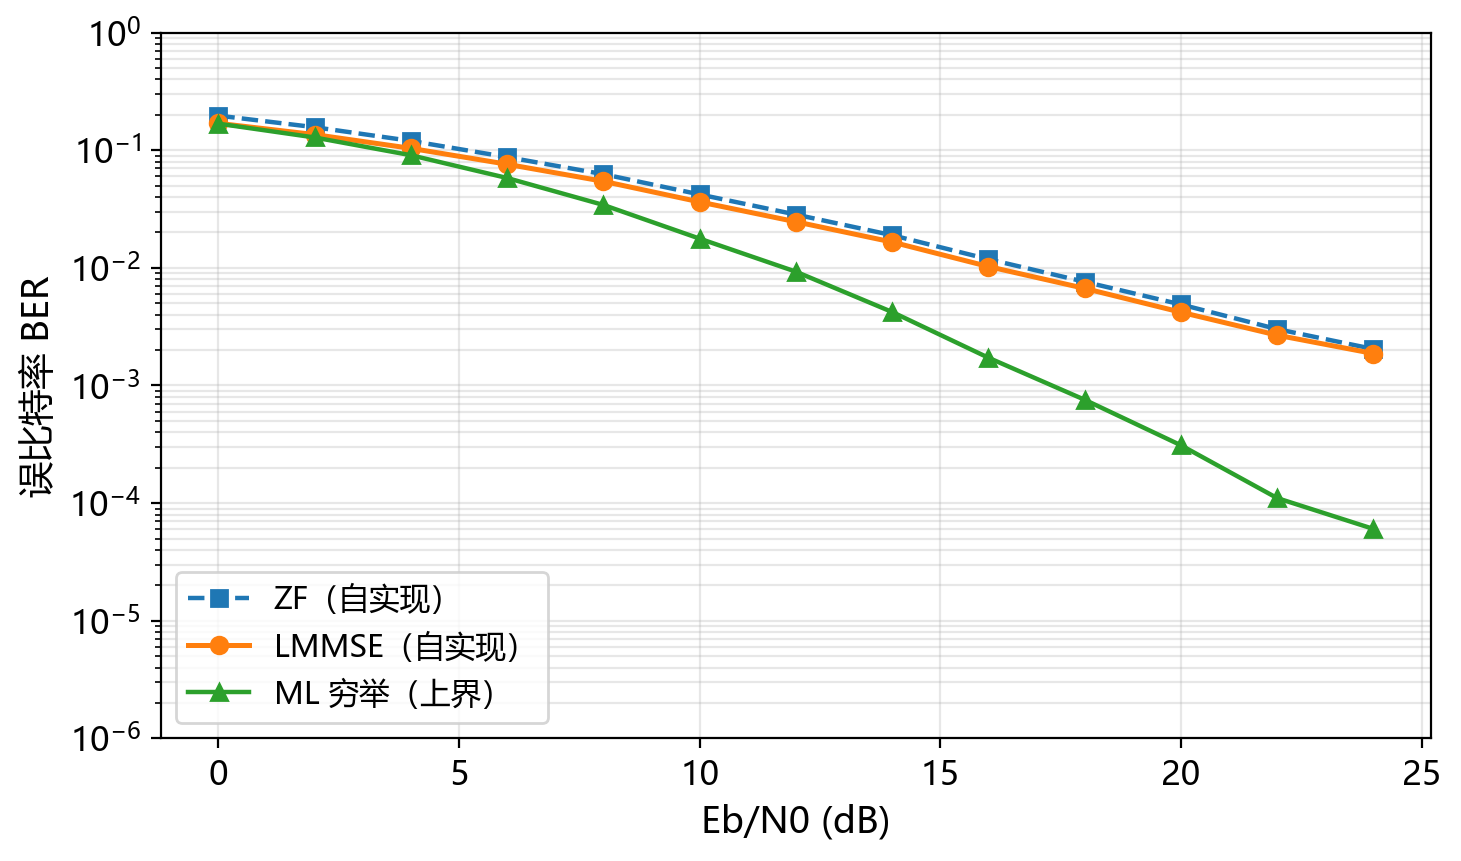

已保存数据：03H_detector_ber_16qam.csv
表 5  检测器增益与分集阶数（目标 BER = 1e-2，Eb/N0 单位 dB）
  配置                       所需 Eb/N0   相对同调制LMMSE   实测分集阶数
  2x2 QPSK ZF                   13.93          +1.86     0.97
  2x2 QPSK LMMSE                12.07          +0.00     0.98
  2x2 QPSK ML                    6.94          -5.13     1.88
  2x2 16-QAM ZF                 16.76          +0.65     0.96
  2x2 16-QAM LMMSE              16.12          +0.00     0.93
  2x2 16-QAM ML                 11.77          -4.35     1.91
  1x1 SISO QPSK（理论）             13.85          +1.78     1.00
  注：相对同调制 LMMSE 为正表示需要更高 Eb/N0（即性能更差）；分集阶数由 BER 在 1e-2~1e-4 区间的斜率估计。
已保存数据：03H_gain_analysis.csv

===== 03H MIMO 检测实验结论 =====
[1] 低信噪比（Eb/N0 = 6 dB）：LMMSE 的 BER 比 ZF 低 31.4%，ML 又比 LMMSE 低 60.6%——正则化项 N0*I 抑制了 ZF 对病态信道的噪声放大。
[2] 达到 BER = 1e-2 所需 Eb/N0：ZF 13.93 dB -> LMMSE 12.07 dB（省 1.86 dB）-> ML 6.94 dB（再省 5.13 dB）。
[3] 高信噪比（Eb/N0 = 18 dB）：ML 的 BER 比 LMMSE 低 96.8%；实测分集阶数 ML≈1.88、LMMSE≈0.98、ZF≈0.97，即线性检测只剩约 1 阶分集，ML 达到 2 阶。
[4] 与

In [5]:
# 补充（高阶调制与增益量化）：16-QAM 2x2 MIMO 的 ZF / LMMSE / ML 对比
torch.manual_seed(2028)
sionna_config.seed = 2028

_QAM16_LEVELS = torch.tensor([-3.0, -1.0, 1.0, 3.0], device=DEVICE) / np.sqrt(10.0)
QAM16_POINTS = torch.complex(
    torch.tensor([-3.0, -3.0, -3.0, -3.0, -1.0, -1.0, -1.0, -1.0,
                  1.0, 1.0, 1.0, 1.0, 3.0, 3.0, 3.0, 3.0], device=DEVICE),
    torch.tensor([-3.0, -1.0, 1.0, 3.0, -3.0, -1.0, 1.0, 3.0,
                  -3.0, -1.0, 1.0, 3.0, -3.0, -1.0, 1.0, 3.0], device=DEVICE),
) / np.sqrt(10.0)


def qam16_map(bits):
    """16-QAM Gray 映射：b0/b1 定符号，b2/b3 定幅度 (1 或 3)，Es = 1。"""
    i = (1.0 - 2.0 * bits[:, 0].float()) * (1.0 + 2.0 * bits[:, 2].float()) / np.sqrt(10.0)
    q = (1.0 - 2.0 * bits[:, 1].float()) * (1.0 + 2.0 * bits[:, 3].float()) / np.sqrt(10.0)
    return torch.complex(i, q).to(torch.complex64)


def _nearest_level(x):
    d = (x.unsqueeze(-1) - _QAM16_LEVELS).abs()
    return d.argmin(dim=-1)


def qam16_demap(x):
    """16-QAM 逐维最近电平判决并 Gray 反映射（0: -3, 1: -1, 2: +1, 3: +3）。"""
    li = _nearest_level(x.real)
    lq = _nearest_level(x.imag)
    return torch.stack(
        [
            (li < 2).to(torch.int64),
            (lq < 2).to(torch.int64),
            ((li == 0) | (li == 3)).to(torch.int64),
            ((lq == 0) | (lq == 3)).to(torch.int64),
        ],
        dim=1,
    )


ebno_cmp16 = np.arange(0, 25, 2)
qam16_res = simulate_linear_ml(
    ebno_cmp16, batch_size=40000, num_reps=3, mbs=4,
    mapper_fn=qam16_map, demapper_fn=qam16_demap, points=QAM16_POINTS,
)

print("表 4  2x2 MIMO 16-QAM 三种检测器的误比特率（每点约 1x10^6 bit）")
print("  Eb/N0 (dB)        ZF        LMMSE           ML")
for _i, _e in enumerate(ebno_cmp16):
    print(f"  {_e:>8.0f}   {qam16_res['zf'][_i]:.3e}   {qam16_res['lmmse'][_i]:.3e}   "
          f"{qam16_res['ml'][_i]:.3e}")

fig, ax = plt.subplots(figsize=(7.5, 4.5))
ax.semilogy(ebno_cmp16, qam16_res["zf"] + 1e-6, "s--", lw=1.6, ms=6, label="ZF（自实现）")
ax.semilogy(ebno_cmp16, qam16_res["lmmse"] + 1e-6, "o-", lw=1.8, ms=6, label="LMMSE（自实现）")
ax.semilogy(ebno_cmp16, qam16_res["ml"] + 1e-6, "^-", lw=1.6, ms=6, label="ML 穷举（上界）")
ax.set_xlabel("Eb/N0 (dB)")
ax.set_ylabel("误比特率 BER")
ax.set_ylim(1e-6, 1.0)
ax.grid(True, which="both", alpha=0.3)
ax.legend(loc="lower left")
plt.tight_layout()
plt.savefig(FIG_DIR / "03H_detector_ber_16qam.png", dpi=200, bbox_inches="tight")
print("图题：2x2 MIMO 16-QAM 下 ZF / LMMSE / ML 检测器的误比特率对比")
plt.show()

pd.DataFrame({"ebno_db": ebno_cmp16, **{f"ber_{k}": v for k, v in qam16_res.items()}}).to_csv(
    DATA_DIR / "03H_detector_ber_16qam.csv", index=False, encoding="utf-8-sig"
)
print("已保存数据：03H_detector_ber_16qam.csv")

# --- 增益与分集阶数量化 ---
def required_ebno(ber_curve, ebno_grid, target):
    """在 log10(BER) 上线性内插，求达到目标 BER 所需的 Eb/N0（dB）。"""
    ber_curve = np.asarray(ber_curve, dtype=float)
    ebno_grid = np.asarray(ebno_grid, dtype=float)
    valid = ber_curve > 0
    if not np.any(valid) or ber_curve[valid].max() < target or ber_curve[valid].min() > target:
        return np.nan
    y = np.log10(ber_curve[valid])
    x = ebno_grid[valid]
    order = np.argsort(y)
    return float(np.interp(np.log10(target), y[order], x[order]))


def diversity_order(ber_curve, ebno_grid, lo=1e-4, hi=1e-2):
    """用高信噪比段的 log(BER)-Eb/N0 斜率估计分集阶数（每 10 dB 降一个数量级记 1 阶）。"""
    ber_curve = np.asarray(ber_curve, dtype=float)
    ebno_grid = np.asarray(ebno_grid, dtype=float)
    mask = (ber_curve > 0) & (ber_curve <= hi) & (ber_curve >= lo)
    if mask.sum() < 3:                    # 高信噪比点太少时退化为更宽区间
        mask = (ber_curve > 0) & (ber_curve <= 1e-1)
    if mask.sum() < 2:
        return np.nan
    slope = np.polyfit(ebno_grid[mask], np.log10(ber_curve[mask]), 1)[0]
    return float(-slope / 0.1)


# siso_qpsk_theory 已在模板主实验单元中定义，这里直接复用
_dense = np.linspace(0.0, 30.0, 301)
siso_need = required_ebno(siso_qpsk_theory(_dense), _dense, 1e-2)

# 按调制方式分别求"同一调制下相对 LMMSE"的增益，避免跨调制比较造成误导
_rows = []
_qpsk_lmmse_need = np.nan
for _mod, _grid, _curves in (
    ("2x2 QPSK", ebno_cmp,
     (("ZF", qpsk_res["zf"]), ("LMMSE", qpsk_res["lmmse"]), ("ML", qpsk_res["ml"]))),
    ("2x2 16-QAM", ebno_cmp16,
     (("ZF", qam16_res["zf"]), ("LMMSE", qam16_res["lmmse"]), ("ML", qam16_res["ml"]))),
):
    _need = {_n: required_ebno(_c, _grid, 1e-2) for _n, _c in _curves}
    _ref = _need["LMMSE"]
    if _mod.startswith("2x2 QPSK"):
        _qpsk_lmmse_need = _ref
    for _n, _c in _curves:
        _rows.append((f"{_mod} {_n}", _need[_n],
                      (_need[_n] - _ref) if np.isfinite(_need[_n]) else np.nan,
                      diversity_order(_c, _grid)))

_rows.append(("1x1 SISO QPSK（理论）", siso_need,
              siso_need - _qpsk_lmmse_need if np.isfinite(siso_need) else np.nan, 1.0))

print("表 5  检测器增益与分集阶数（目标 BER = 1e-2，Eb/N0 单位 dB）")
print("  配置                       所需 Eb/N0   相对同调制LMMSE   实测分集阶数")
for _n, _e, _d, _div in _rows:
    _e_txt = f"{_e:>9.2f}" if np.isfinite(_e) else f"{'—':>9s}"
    _d_txt = f"{_d:>+15.2f}" if np.isfinite(_d) else f"{'—':>15s}"
    _div_txt = f"{_div:>9.2f}" if np.isfinite(_div) else f"{'—':>9s}"
    print(f"  {_n:<26s}{_e_txt}{_d_txt}{_div_txt}")
print("  注：相对同调制 LMMSE 为正表示需要更高 Eb/N0（即性能更差）；分集阶数由 BER 在 1e-2~1e-4 区间的斜率估计。")

df_gain = pd.DataFrame(_rows, columns=["config", "ebno_for_ber_1e-2_db",
                                       "gain_vs_lmmse_db", "diversity_order"])
df_gain.to_csv(DATA_DIR / "03H_gain_analysis.csv", index=False, encoding="utf-8-sig")
print("已保存数据：03H_gain_analysis.csv")

# --- 最终结论 ---
def _idx(ebno):
    """在采样网格上找最接近给定 Eb/N0 的下标。"""
    return int(np.argmin(np.abs(ebno_cmp - ebno)))


_i_low = _idx(6.0)
_i_high = _idx(18.0)
_gap_zf_lmmse_db = _rows[0][1] - _rows[1][1]        # ZF 比 LMMSE 多需要的 Eb/N0
_ml_gain_db = _rows[1][1] - _rows[2][1]             # ML 相对 LMMSE 节省的 Eb/N0
_lmmse_gain_low = (qpsk_res["zf"][_i_low] - qpsk_res["lmmse"][_i_low]) / qpsk_res["zf"][_i_low]
_ml_gain_low = (qpsk_res["lmmse"][_i_low] - qpsk_res["ml"][_i_low]) / qpsk_res["lmmse"][_i_low]
_ml_lmmse_gap_high = (qpsk_res["lmmse"][_i_high] - qpsk_res["ml"][_i_high]) / qpsk_res["lmmse"][_i_high]

print("\n===== 03H MIMO 检测实验结论 =====")
print(f"[1] 低信噪比（Eb/N0 = {ebno_cmp[_i_low]:.0f} dB）：LMMSE 的 BER 比 ZF 低 {_lmmse_gain_low * 100:.1f}%，"
      f"ML 又比 LMMSE 低 {_ml_gain_low * 100:.1f}%——正则化项 N0*I 抑制了 ZF 对病态信道的噪声放大。")
print(f"[2] 达到 BER = 1e-2 所需 Eb/N0：ZF {_rows[0][1]:.2f} dB -> LMMSE {_rows[1][1]:.2f} dB"
      f"（省 {_gap_zf_lmmse_db:.2f} dB）-> ML {_rows[2][1]:.2f} dB（再省 {_ml_gain_db:.2f} dB）。")
print(f"[3] 高信噪比（Eb/N0 = {ebno_cmp[_i_high]:.0f} dB）：ML 的 BER 比 LMMSE 低 {_ml_lmmse_gap_high * 100:.1f}%；"
      f"实测分集阶数 ML≈{_rows[2][3]:.2f}、LMMSE≈{_rows[1][3]:.2f}、ZF≈{_rows[0][3]:.2f}，"
      f"即线性检测只剩约 1 阶分集，ML 达到 2 阶。")
print(f"[4] 与 1x1 SISO QPSK 理论值 {siso_need:.2f} dB 对比：2x2 ML 低 {siso_need - _rows[2][1]:.2f} dB，"
      f"而 2x2 LMMSE/ZF 分别高 {_rows[1][1] - siso_need:.2f}/{_rows[0][1] - siso_need:.2f} dB——"
      f"空间复用带来的流间干扰抵消了天线阵列增益，必须靠 ML 类非线性检测才能兑现。")
print("实验完成：三种检测器的实现与 Sionna 库函数互相印证，结论与 MIMO 检测理论一致。")